# 02 · Rel-MF on uniform-exposure test sets

**Question.** Does Rel-MF (Saito et al., WSDM 2020) beat naive matrix factorisation and WMF, one of the
paper's two Yahoo! baselines, when the test set has uniform exposure? And where does a gain come from: the popularity shape of
the propensity, the correction on the negative term, or plain up-weighting of positives?
What happens when the unbiased risk goes negative?

**Setup.** The pointwise families share one trainer and one objective,
`J = Σ w¹ (1 − σ)² + w⁰ σ² + (λ/2)(‖U‖² + ‖V‖²)`, computed exactly over all user-item pairs
with full-batch Adam. They differ in their weights, except nnPU, which keeps Rel-MF's weights at M = 0
and changes the step. BPR-MF and EASE are separate baselines with their own objectives.

| Family | w¹ | w⁰ | Meaning |
|---|---|---|---|
| Naive MF | Y | 1 − Y | Unlabelled means negative |
| WMF | c′Y | 1 − Y | Up-weight positives, keep negatives |
| SCAR | Y/c | 1 − Y/c | Constant exposure c, the uPU risk of du Plessis et al. |
| Rel-MF | Y/θ̄ | 1 − Y/θ̄ | Exposure θ̂ from item popularity (Eq. 12), clipped estimator (Eq. 11), SAR PU |
| Rel-MF + nnPU | same, M = 0 | same, M = 0 | If R̂_n < 0, step on −R̂_n (Kiryo et al., Algorithm 1) |
| Rel-MF balanced | bY/θ̄ | a(1 − Y) + bY(1 − 1/θ̄) | Expected objective of the official code's 50/50 minibatch |

In these families `λ = λ̃ · w̄_pos`, with `w̄_pos` the mean of `w¹` on `Y = 1`, so the regulariser scales with each family's positive weights.
Each family tunes its own λ̃ on {0.3, 1, 3, 10}, extended downward for families whose validation
winner sat on the edge (`EXTRA_LAM` in `src/config.py`). Step budgets differ for the same reason: 6000 for naive MF, 3000 for SCAR, nnPU,
balanced and η = 0.25, 1500 for WMF and η = 1. Rel-MF's winners were not near the end of its budget; it also gets 3000 so that its last-step
comparison with nnPU is at the same step. Rule A is the paper's selection statistic
(per-user SNIPS DCG@5 on held-out logged positives); rule B is per-user DCG@5 on `val_B`, a
slice of 10% of the uniform-exposure users. Test metrics are logged along each trajectory for
the plots, and no selection reads them. Finals: each family's winner at seed 42 under each rule, re-fit with seeds 42, 43, 44 (popularity and EASE once; η = 0.25 and η = 1 rule A only),
step re-selected per seed. Differences are user-level paired bootstrap CIs on seed-averaged
per-user metrics. "Held" means the CI lower bound is above 0 and all three seeds agree.

In [1]:
import sys

sys.path[:0] = ["../src", "src"]  # from notebooks/ or from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import AQUA, BLUE, DIM, GRAY, INK2, LABELS, MPL, ORANGE, RESULTS, RULES, SENS_DIMS, THRESHOLD, last_step
from data import load, theta
from evaluate import boot_idx, compare, floors, load_scores, load_traj, paired_ci, per_user, reliability, score_vectors, seed_metrics, select, verdict

plt.rcParams.update(MPL)
RESULTS.mkdir(exist_ok=True)
MAIN = ["popularity", "naive", "bpr", "ease", "wmf", "scar", "relmf", "nnpu", "balanced"]
METRICS = [f"{m}@{k}" for m in ("DCG", "Recall", "AP") for k in (1, 3, 5)]


class Finals:
    """One dataset's final fits, with the all-item and rare-credit readings of the test users."""

    def __init__(self, name):
        self.d, self.scores, self.traj = load(name), load_scores(name), load_traj(name)
        L = self.d.test
        self.L, self.rare_rel = L, L.R * self.d.rare[L.I]
        keep, keep_r = L.R.sum(1) > 0, self.rare_rel.sum(1) > 0
        self.random, self.ideal = floors(L.R[keep].sum(1), L.M[keep].sum(1))
        self.random_r, self.ideal_r = floors(self.rare_rel[keep_r].sum(1), L.M[keep_r].sum(1))
        self.idx, self.idx_r = boot_idx(keep.sum()), boot_idx(keep_r.sum())
        self._cache = {}

    def all(self, family, rule):
        key = family, rule, "all"
        if key not in self._cache:
            self._cache[key] = seed_metrics(score_vectors(self.scores, family, rule), self.L)
        return self._cache[key]

    def rare(self, family, rule):
        key = family, rule, "rare"
        if key not in self._cache:
            self._cache[key] = seed_metrics(score_vectors(self.scores, family, rule), self.L, rel=self.rare_rel)
        return self._cache[key]


def main_table(F, metrics):
    rows = {"Random (analytic)": {**{m: F.random[m].mean() for m in metrics}, "Rare@5": F.random_r["DCG@5"].mean()}}
    for f in MAIN:
        a, ra = F.all(f, "A")[0], F.rare(f, "A")[0]
        b, rb = F.all(f, "B")[0], F.rare(f, "B")[0]
        rows[LABELS[f]] = {**{m: a[m].mean() for m in metrics}, "Rare@5": ra["DCG@5"].mean(),
                           "B: DCG@5": b["DCG@5"].mean(), "B: Rare@5": rb["DCG@5"].mean()}
    rows["Ideal (analytic)"] = {**{m: F.ideal[m].mean() for m in metrics}, "Rare@5": F.ideal_r["DCG@5"].mean()}
    return pd.DataFrame(rows).T


def diff_table(F, pairs, rules=("A", "B")):
    rows = []
    for x, y in pairs:
        for rule in rules:
            for label, get, idx, ideal in (("DCG@5", F.all, F.idx, F.ideal["DCG@5"].mean()),
                                           ("Rare-credit DCG@5", F.rare, F.idx_r, F.ideal_r["DCG@5"].mean())):
                rows.append({"comparison": f"{LABELS[x]} vs {LABELS[y]}", "rule": rule, "metric": label,
                             **compare(get(x, rule), get(y, rule), "DCG@5", idx, ideal)})
    return pd.DataFrame(rows)


def md(df, **kw):
    """Markdown with blanks for missing values."""
    return df.astype(object).where(df.notna(), None).to_markdown(floatfmt=".4f", **kw)


def show_diffs(df):
    """Display table. "No clear difference" means the CI covers 0."""
    out = pd.DataFrame({"comparison": df.comparison, "rule": df["rule"], "metric": df.metric,
                        "diff": df["diff"].map("{:+.4f}".format),
                        "95% CI": [f"[{a:+.4f}, {b:+.4f}]" for a, b in zip(df.lo, df.hi)],
                        "relative gain": df.rel_gain.map("{:+.1%}".format), "headroom share": df.headroom.map("{:+.1%}".format),
                        "seeds agree": df.same_sign.map({True: "yes", False: "no"}),
                        "reading": ["higher" if a > 0 else "lower" if b < 0 else "no clear difference" for a, b in zip(df.lo, df.hi)]})
    return out.to_markdown(index=False, disable_numparse=True)


def write(path, *parts):
    (RESULTS / path).write_text("\n".join(parts) + "\n")


Y = Finals("yahoo")

## 1. Main table (Yahoo! R3)

Per-user metrics on the user's own test items, over users with at least one relevant test
item (2,197 users). `Rare@5` is rare-credit DCG@5: the user's full candidate list is ranked, and
only rare relevant items (bottom 50% of items by popularity) score, over users with at least one
such item (1,073 users). Columns without a prefix are rule A.

In [2]:
table = main_table(Y, METRICS)
main_md = md(table)
print(main_md)
main5_md = md(main_table(Y, ["DCG@5", "Recall@5", "AP@5"]))

|                                           |   DCG@1 |   DCG@3 |   DCG@5 |   Recall@1 |   Recall@3 |   Recall@5 |   AP@1 |   AP@3 |   AP@5 |   Rare@5 |   B: DCG@5 |   B: Rare@5 |
|:------------------------------------------|--------:|--------:|--------:|-----------:|-----------:|-----------:|-------:|-------:|-------:|---------:|-----------:|------------:|
| Random (analytic)                         |  0.1961 |  0.4179 |  0.5783 |     0.1000 |     0.3000 |     0.5000 | 0.1961 | 0.2149 | 0.2623 |   0.4289 |            |             |
| Popularity                                |  0.3887 |  0.6631 |  0.8166 |     0.2334 |     0.4867 |     0.6699 | 0.3887 | 0.3904 | 0.4350 |   0.0847 |     0.8166 |      0.0847 |
| Naive MF                                  |  0.4580 |  0.7430 |  0.8848 |     0.2834 |     0.5325 |     0.6979 | 0.4580 | 0.4493 | 0.4883 |   0.4385 |     0.9063 |      0.3397 |
| BPR-MF                                    |  0.5124 |  0.8293 |  0.9755 |     0.3182 |     0.5966 

In [3]:
DIFFS = [("relmf", "naive"), ("nnpu", "relmf"), ("balanced", "relmf"), ("ease", "relmf"), ("bpr", "relmf")]
diffs = diff_table(Y, DIFFS)
diffs_md = show_diffs(diffs)
print(diffs_md)
head = diffs[diffs.comparison == f"{LABELS['relmf']} vs {LABELS['naive']}"]
verdicts = "\n".join(f"Rel-MF vs naive MF, rule {r['rule']}, {r.metric}: {verdict(r)}" for _, r in head.iterrows())
print(verdicts)

| comparison                                          | rule   | metric            | diff    | 95% CI             | relative gain   | headroom share   | seeds agree   | reading             |
|:----------------------------------------------------|:-------|:------------------|:--------|:-------------------|:----------------|:-----------------|:--------------|:--------------------|
| Rel-MF vs Naive MF                                  | A      | DCG@5             | +0.0883 | [+0.0764, +0.1013] | +10.0%          | +14.3%           | yes           | higher              |
| Rel-MF vs Naive MF                                  | A      | Rare-credit DCG@5 | +0.0434 | [+0.0253, +0.0594] | +9.9%           | +5.3%            | yes           | higher              |
| Rel-MF vs Naive MF                                  | B      | DCG@5             | +0.0653 | [+0.0530, +0.0787] | +7.2%           | +11.0%           | yes           | higher              |
| Rel-MF vs Naive MF                         

Rare items also have a restricted reading: the candidate list keeps only rare items, as the official
code does at `n_i ≤ 500`. With the bottom 50%, Yahoo! users keep about 5 of their 10 candidates, so Recall@5 saturates
(a random ranking already scores 0.89) and only K = 1, 3 are informative.

In [4]:
d, L = Y.d, Y.L
mask = L.M & d.rare[L.I]
rows = {}
for f in ["naive", "wmf", "scar", "relmf", "nnpu", "balanced"]:
    m = seed_metrics(score_vectors(Y.scores, f, "A"), L, rel=Y.rare_rel, mask=mask)[0]
    c = Y.rare(f, "A")[0]
    rows[LABELS[f]] = {"Credit DCG@1": c["DCG@1"].mean(), "Credit DCG@3": c["DCG@3"].mean(), "Credit DCG@5": c["DCG@5"].mean(),
                       "Restricted DCG@1": m["DCG@1"].mean(), "Restricted DCG@3": m["DCG@3"].mean(),
                       "Restricted Recall@1": m["Recall@1"].mean(), "Restricted Recall@3": m["Recall@3"].mean(),
                       "Restricted Recall@5 (saturated)": m["Recall@5"].mean()}
keep = Y.rare_rel.sum(1) > 0
rr, ri = floors(Y.rare_rel[keep].sum(1), mask[keep].sum(1))
rows["Random (analytic)"] = {"Credit DCG@1": Y.random_r["DCG@1"].mean(), "Credit DCG@3": Y.random_r["DCG@3"].mean(), "Credit DCG@5": Y.random_r["DCG@5"].mean(),
                             "Restricted DCG@1": rr["DCG@1"].mean(), "Restricted DCG@3": rr["DCG@3"].mean(),
                             "Restricted Recall@1": rr["Recall@1"].mean(), "Restricted Recall@3": rr["Recall@3"].mean(),
                             "Restricted Recall@5 (saturated)": rr["Recall@5"].mean()}
rare_md = pd.DataFrame(rows).T.to_markdown(floatfmt=".4f")
print(rare_md)
n_rare_users, n_rare_pos = int(keep.sum()), int(Y.rare_rel.sum())
print(f"users with a rare relevant test item: {n_rare_users}; rare positives: {n_rare_pos}; mean rare candidates per user: {mask.sum(1).mean():.2f}")
rest = {(f, r): seed_metrics(score_vectors(Y.scores, f, r), L, rel=Y.rare_rel, mask=mask) for f in ("wmf", "scar", "relmf", "balanced") for r in "AB"}
rest_md = show_diffs(pd.DataFrame([{"comparison": f"{LABELS[a]} vs {LABELS[b]}", "rule": r, "metric": f"Restricted {k}", **compare(rest[a, r], rest[b, r], k, Y.idx_r, ri[k].mean())}
                                   for r in "AB" for k in ("DCG@1", "DCG@3") for a, b in (("wmf", "balanced"), ("scar", "balanced"), ("wmf", "relmf"), ("scar", "relmf"))]))
rest_b = ", ".join(f"{LABELS[f]} {rest[f, 'B'][0]['DCG@1'].mean():.4f}" for f in ("wmf", "scar", "relmf", "balanced"))
print(rest_md)
write("02_yahoo.md", "### Main table @5, Yahoo! R3 (rule A unless prefixed with B; 3 seeds)\n", main5_md,
      "\n### Main table, all cut-offs\n", main_md,
      "\n### Paired differences (user-level bootstrap, 3 seeds)\n", diffs_md, "\n" + verdicts.replace("\n", "  \n"),
      "\n### Rare items, two readings (rule A)\n", rare_md,
      f"\nUsers with a rare relevant test item: {n_rare_users}. Rare positives: {n_rare_pos}. Mean rare candidates per user: {mask.sum(1).mean():.2f}.",
      "\n### Restricted reading, paired differences (3 seeds)\n", rest_md, f"\nRestricted DCG@1 under rule B: {rest_b}.")

|                                           |   Credit DCG@1 |   Credit DCG@3 |   Credit DCG@5 |   Restricted DCG@1 |   Restricted DCG@3 |   Restricted Recall@1 |   Restricted Recall@3 |   Restricted Recall@5 (saturated) |
|:------------------------------------------|---------------:|---------------:|---------------:|-------------------:|-------------------:|----------------------:|----------------------:|----------------------------------:|
| Naive MF                                  |         0.0944 |         0.2789 |         0.4385 |             0.4362 |             0.7585 |                0.3259 |                0.7142 |                            0.9277 |
| WMF                                       |         0.1302 |         0.3310 |         0.4719 |             0.5266 |             0.8411 |                0.4088 |                0.7723 |                            0.9394 |
| SCAR (constant θ)                         |         0.1168 |         0.3262 |         0.4681 |            

| comparison                                                     | rule   | metric           | diff    | 95% CI             | relative gain   | headroom share   | seeds agree   | reading             |
|:---------------------------------------------------------------|:-------|:-----------------|:--------|:-------------------|:----------------|:-----------------|:--------------|:--------------------|
| WMF vs Rel-MF balanced (official-code objective)               | A      | Restricted DCG@1 | +0.0227 | [+0.0068, +0.0410] | +4.5%           | +4.6%            | yes           | higher              |
| SCAR (constant θ) vs Rel-MF balanced (official-code objective) | A      | Restricted DCG@1 | +0.0227 | [+0.0009, +0.0460] | +4.5%           | +4.6%            | yes           | higher              |
| WMF vs Rel-MF                                                  | A      | Restricted DCG@1 | +0.0280 | [+0.0043, +0.0522] | +5.6%           | +5.6%            | yes           | higher           

## 2. Where does the gain come from?

WMF and SCAR pair up through `c′ = 1/c`, since `SCAR(c) = WMF(1/c) + (1 − 1/c) Σ_{Y=1} σ²`.
Reading the three columns together separates three explanations:

* (a) WMF ≈ SCAR ≈ Rel-MF: the gain is positive re-weighting.
* (b) WMF < SCAR ≈ Rel-MF: the gain is the PU correction on the negative term.
* (c) SCAR < Rel-MF: the gain is the popularity shape of θ̂.

The first table uses the grid (seed 42, λ̃ and step chosen by each rule inside each cell). The
second compares family winners with 3 seeds. SCAR at c′ = 500 is a control outside the SCAR grid: balanced weights positives about 500 times
unlabelled pairs on average, and without this cell nothing near that scale has the PU term and no shape.

In [5]:
T = Y.traj[Y.traj.phase == "grid"]


def best_cell(df, rule="A"):
    return df.loc[df[RULES[rule]].idxmax()]


def cell(r):
    return f"{r.test_dcg5:.4f} / {r.rare_credit5:.4f}"


rows = []
for f in MAIN + ["relmf_eta025", "relmf_eta1"]:
    for rule in ("A", "B") if f in MAIN else ("A",):
        r = select(T, f, rule)
        rows.append({"family": LABELS[f].split(" (")[0], "rule": rule, "c′ (WMF) = 1/c (SCAR)": 1 / r.c if f == "scar" else r.c, "η": r.eta, "M": r.M, "λ̃": r.lam_rel, "step": r.step, "test DCG@5": r.test_dcg5, "rare-credit": r.rare_credit5})
winners = pd.DataFrame(rows)
winners_md = winners.astype(object).where(winners.notna(), None).to_markdown(index=False, floatfmt=(".4g",) * 7 + (".4f",) * 2)
print(winners_md)

CG = Y.traj[Y.traj.phase == "control_grid"]


def cells(df, rule):
    return cell(best_cell(df, rule)) if len(df) else "not in grid"


rows = []
for c in (3, 10, 30, 100, 300, 500, 1000):
    w, sc = T[(T.family == "wmf") & (T.c == c)], T[(T.family == "scar") & (np.isclose(T.c, 1 / c))]
    sc = CG if c == 500 else sc
    rows.append({"c′ (WMF) = 1/c (SCAR)": c, "WMF, rule A": cells(w, "A"), "SCAR, rule A": cells(sc, "A"), "WMF, rule B": cells(w, "B"), "SCAR, rule B": cells(sc, "B")})
for f in ("relmf", "balanced"):
    rows.append({"c′ (WMF) = 1/c (SCAR)": LABELS[f].split(" (")[0], "WMF, rule A": cells(T[T.family == f], "A"), "SCAR, rule A": "", "WMF, rule B": cells(T[T.family == f], "B"), "SCAR, rule B": ""})
paired = pd.DataFrame(rows).set_index("c′ (WMF) = 1/c (SCAR)")
print(paired.to_markdown())

decomp = diff_table(Y, [("wmf", "naive"), ("scar", "wmf"), ("relmf", "scar"), ("relmf", "wmf"), ("balanced", "wmf"), ("balanced", "scar"), ("balanced", "scar_c500")])
decomp_md = show_diffs(decomp)
print(decomp_md)


def compact(df):
    """One row per comparison, one cell per metric and rule. Bold when the 95% CI excludes 0."""
    cells = [f"**{v:+.4f}** [{a:+.4f}, {b:+.4f}]" if a > 0 or b < 0 else f"{v:+.4f} [{a:+.4f}, {b:+.4f}]" for v, a, b in zip(df["diff"], df.lo, df.hi)]
    t = df.assign(cell=cells, col=df.metric.map({"DCG@5": "All items", "Rare-credit DCG@5": "Rare-credit"}) + ", rule " + df["rule"])
    cols = ["All items, rule A", "Rare-credit, rule A", "All items, rule B", "Rare-credit, rule B"]
    out = t.pivot(index="comparison", columns="col", values="cell").loc[t.comparison.unique(), cols]
    return out.rename(index=lambda x: x.replace(" (official-code objective)", "").replace(" (constant θ)", "")).to_markdown(disable_numparse=True)


compact_md = compact(pd.concat([head, decomp, diffs[diffs.comparison != head.comparison.iloc[0]]]))
print(compact_md)


def ci_sign(table, comparison, rule, metric):
    r = table[(table.comparison == comparison) & (table["rule"] == rule) & (table.metric == metric)].iloc[0]
    return ">" if r.lo > 0 else "<" if r.hi < 0 else "≈"

| family           | rule   |   c′ (WMF) = 1/c (SCAR) |    η |   M |       λ̃ |   step |   test DCG@5 |   rare-credit |
|:-----------------|:-------|------------------------:|-----:|----:|--------:|-------:|-------------:|--------------:|
| Popularity       | A      |                         |      |     |         |      0 |       0.8166 |        0.0847 |
| Popularity       | B      |                         |      |     |         |      0 |       0.8166 |        0.0847 |
| Naive MF         | A      |                         |      |     |    1    |   4000 |       0.8944 |        0.4137 |
| Naive MF         | B      |                         |      |     |    1    |   2300 |       0.9059 |        0.3287 |
| BPR-MF           | A      |                         |      |     |    0.01 |     57 |       0.9712 |        0.4379 |
| BPR-MF           | B      |                         |      |     |    0.01 |     68 |       0.9713 |        0.4320 |
| EASE             | A      |                  

Winners compare different scales: under rule B, SCAR at c′ = 30 against WMF at c′ = 300. The next cell splits that gap, and then reads the PU term
alone: SCAR against WMF at the same c′ and λ̃ (seed 42, no CIs, since scores are stored only for winners).

In [6]:
FT = Y.traj[Y.traj.phase == "final"]


def at_b(family, c):
    r = FT[(FT.family == family) & np.isclose(FT.c, c)]
    return r.loc[r.groupby("seed").val_b.idxmax(), ["test_dcg5", "rare_credit5"]].mean()


scar_b, w100, w300 = at_b("scar", 1 / 30), at_b("wmf", 100), at_b("wmf", 300)
same = []
for c in (3, 10, 30, 100):
    for lam in (0.3, 1, 3, 10):
        w = T[(T.family == "wmf") & (T.c == c) & (T.lam_rel == lam)]
        sc = T[(T.family == "scar") & np.isclose(T.c, 1 / c) & (T.lam_rel == lam)]
        for rule in "AB":
            rw, rs = best_cell(w, rule), best_cell(sc, rule)
            same.append(dict(rule=rule, all_items=rs.test_dcg5 - rw.test_dcg5, rare=rs.rare_credit5 - rw.rare_credit5))
same = pd.DataFrame(same).groupby("rule").agg(lambda x: (x > 0).sum())
pu_lines = [f"Rule B, 3 seeds, test DCG@5 / rare-credit, no CI: SCAR c′ = 30 minus WMF c′ = 100: {scar_b.test_dcg5 - w100.test_dcg5:+.4f} / {scar_b.rare_credit5 - w100.rare_credit5:+.4f}. "
            f"WMF c′ = 300 minus WMF c′ = 100: {w300.test_dcg5 - w100.test_dcg5:+.4f} / {w300.rare_credit5 - w100.rare_credit5:+.4f}.",
            f"Same c′ and λ̃, cells of 16 where SCAR is above WMF (seed 42): rule A all items {same.loc['A', 'all_items']}, rare-credit {same.loc['A', 'rare']}; rule B all items {same.loc['B', 'all_items']}, rare-credit {same.loc['B', 'rare']}."]
bal = best_cell(T[T.family == "balanced"])
beat = T[(T.family != "balanced") & (T.test_dcg5 > bal.test_dcg5) & (T.rare_credit5 > bal.rare_credit5)]
pu_lines.append(f"Grid points of other families above balanced's rule A pick on both metrics (seed 42): " + ", ".join(f"{r.family} c′={r.c:g} λ̃={r.lam_rel:g} step {r.step:.0f}" for r in beat.itertuples()))
cg3 = best_cell(CG[CG.lam_rel == 0.3])
pu_lines.append(f"Control at balanced's rule A λ̃ = 0.3, rule A inside that cell (seed 42): {cg3.test_dcg5:.4f} / {cg3.rare_credit5:.4f}, step {cg3.step:.0f}.")
print("\n".join(pu_lines))

Rule B, 3 seeds, test DCG@5 / rare-credit, no CI: SCAR c′ = 30 minus WMF c′ = 100: +0.0016 / -0.0090. WMF c′ = 300 minus WMF c′ = 100: +0.0130 / -0.0230.
Same c′ and λ̃, cells of 16 where SCAR is above WMF (seed 42): rule A all items 8, rare-credit 13; rule B all items 12, rare-credit 15.
Grid points of other families above balanced's rule A pick on both metrics (seed 42): wmf c′=30 λ̃=1 step 310, wmf c′=30 λ̃=1 step 320, wmf c′=30 λ̃=1 step 330
Control at balanced's rule A λ̃ = 0.3, rule A inside that cell (seed 42): 0.9876 / 0.4896, step 2970.


A popularity shape in the objective is one way to lift rare items. The cheap alternative is a penalty at ranking time on a model already trained:
`score − α · sd(score) · log(n_i + 1)`, no training. I added this after seeing the results, with one penalty form, on the rule B WMF fits.
α comes from `val_B`, per seed: either the top of its all-item DCG@5, or the first α that reaches balanced's rare-credit at DCG@5, 3 or 1.

In [7]:
def penalised(F, family, rule, alpha=None):
    """(all-item, rare-credit) seed_metrics of the penalised scores. alpha = {seed: α}."""
    v = {s_: x - (alpha[s_] if alpha else 0) * x.std() * np.log(F.d.n_i + 1)[F.d.rand[:, 1]] for s_, x in score_vectors(F.scores, family, rule).items()}
    return seed_metrics(v, F.L), seed_metrics(v, F.L, rel=F.rare_rel)


def val_b_dcg(F, x, a, rare=False, K=5):
    V = F.d.val_b
    return per_user(x[V.row] - a * x.std() * np.log(F.d.n_i + 1)[V.I], V, V.R * F.d.rare[V.I] if rare else None, Ks=(K,))[f"DCG@{K}"].mean()


GRID = np.round(np.arange(0, 1.01, 0.02), 2)
wmf_b, bal_b = score_vectors(Y.scores, "wmf", "B"), score_vectors(Y.scores, "balanced", "B")
top = {s_: GRID[np.argmax([val_b_dcg(Y, x, a) for a in GRID])] for s_, x in wmf_b.items()}
match = {K: {s_: next(a for a in GRID if val_b_dcg(Y, x, a, True, K) >= val_b_dcg(Y, bal_b[s_], 0, True, K)) for s_, x in wmf_b.items()} for K in (5, 3, 1)}
rows = []
choices = [(f"top of val_B (α = {[float(v) for v in top.values()]})", top, "WMF", penalised(Y, "wmf", "B"))]
choices += [(f"balanced's val_B rare-credit at DCG@{K} (α = {[float(v) for v in m.values()]})", m, "balanced", penalised(Y, "balanced", "B")) for K, m in match.items()]
for label, alpha, against, ref in choices:
    x = penalised(Y, "wmf", "B", alpha)
    for metric in ("DCG@1", "DCG@3", "DCG@5"):
        for name, i, idx in (("All items", 0, Y.idx), ("Rare-credit", 1, Y.idx_r)):
            rows.append(dict(zip(("α from", "against", "metric", "diff", "low", "high"), (label, against, f"{name} {metric}", *paired_ci(x[i][0][metric], ref[i][0][metric], idx)))))
penalty_md = pd.DataFrame(rows).to_markdown(index=False, floatfmt="+.4f")
print(penalty_md)

| α from                                                         | against   | metric            |    diff |     low |    high |
|:---------------------------------------------------------------|:----------|:------------------|--------:|--------:|--------:|
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | All items DCG@1   | +0.0006 | -0.0055 | +0.0070 |
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | Rare-credit DCG@1 | +0.0261 | +0.0180 | +0.0339 |
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | All items DCG@3   | -0.0006 | -0.0060 | +0.0053 |
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | Rare-credit DCG@3 | +0.0495 | +0.0413 | +0.0570 |
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | All items DCG@5   | -0.0047 | -0.0100 | +0.0007 |
| top of val_B (α = [0.1, 0.18, 0.18])                           | WMF       | Rare-credit DCG@5 

In [8]:
lines = []
for rule in ("A", "B"):
    for metric in ("DCG@5", "Rare-credit DCG@5"):
        a = ci_sign(decomp, f"{LABELS['scar']} vs {LABELS['wmf']}", rule, metric)
        b = ci_sign(decomp, f"{LABELS['relmf']} vs {LABELS['scar']}", rule, metric)
        lines.append(f"Rule {rule}, {metric}: SCAR {a} WMF; Rel-MF {b} SCAR")
print("\n".join(lines))
write("02_decomposition.md", "### WMF(c′) and SCAR(1/c′), with the Rel-MF and balanced winners below: test DCG@5 / rare-credit DCG@5 (seed 42; c′ = 500 is the control)\n",
      paired.to_markdown(), "\n### Family winners (3 seeds)\n", decomp_md, "\n### CI signs\n", "\n".join(f"- {x}" for x in lines),
      "\n### The PU term alone\n", "  \n".join(pu_lines),
      "\n### Popularity penalty at ranking time, WMF rule B against the row named in `against` (3 seeds, no training)\n", penalty_md,
      "\n### All comparisons, difference and 95% CI (3 seeds; bold when the CI excludes 0)\n", compact_md,
      "\n### Each family's winner at seed 42 (finals re-select the step per seed; BPR-MF's step is an epoch, its λ̃ the regulariser; EASE's λ̃ is λ)\n", winners_md)

Rule A, DCG@5: SCAR ≈ WMF; Rel-MF < SCAR
Rule A, Rare-credit DCG@5: SCAR ≈ WMF; Rel-MF ≈ SCAR
Rule B, DCG@5: SCAR < WMF; Rel-MF < SCAR
Rule B, Rare-credit DCG@5: SCAR > WMF; Rel-MF ≈ SCAR


## 3. The accuracy and rare-item frontier

Rare-credit does not move in one direction. It starts near the random level and falls while the model learns popularity; balanced at
λ̃ ≤ 1 is the exception, rising to about 0.46 and dipping only to about 0.40. At small λ̃ it then climbs, for several hundred steps in most
families and thousands in naive MF, and drifts down; at large λ̃ it stays low as the model collapses towards popularity. All-item DCG peaks
at a different step, so a single point hides the trade-off. Each panel shows every (configuration, step) of one family at seed 42, with the
other five in gray. Stars mark the points rules A and B select at seed 42, so they differ a little from the 3-seed tables.

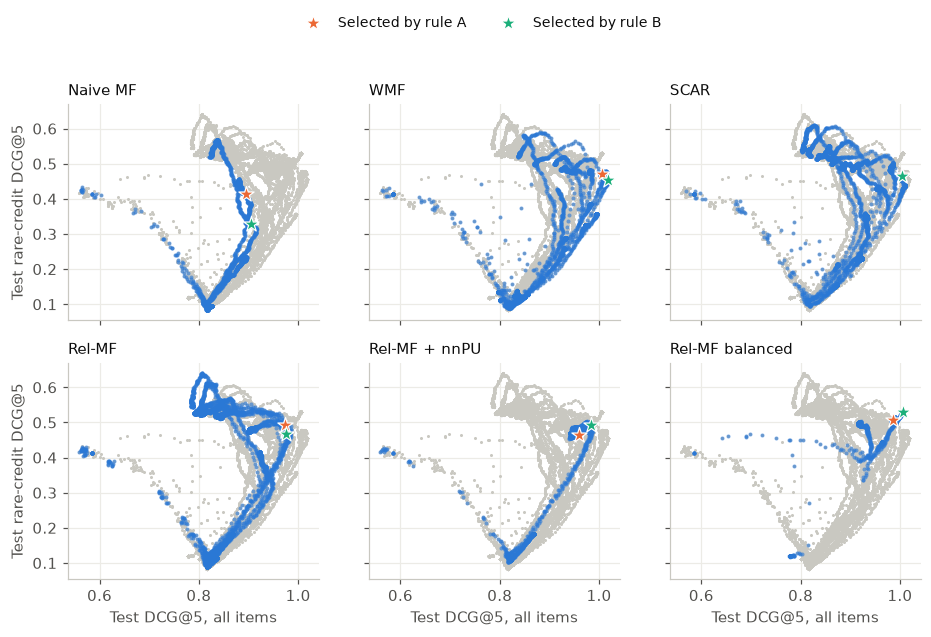

In [9]:
PANELS = ["naive", "wmf", "scar", "relmf", "nnpu", "balanced"]
pts = T[T.family.isin(PANELS)]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharex=True, sharey=True)
for ax, f in zip(axes.flat, PANELS):
    me = pts[pts.family == f]
    ax.scatter(pts.test_dcg5, pts.rare_credit5, s=4, color=GRAY, linewidths=0, rasterized=True)
    ax.scatter(me.test_dcg5, me.rare_credit5, s=7, color=BLUE, alpha=0.6, linewidths=0, rasterized=True)
    for rule, color, label in (("A", ORANGE, "Selected by rule A"), ("B", AQUA, "Selected by rule B")):
        r = select(T, f, rule)
        ax.scatter(r.test_dcg5, r.rare_credit5, s=110, marker="*", color=color, edgecolors="white", linewidths=0.8, zorder=5, label=label)
    ax.set_title(LABELS[f].split(" (")[0])
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 0.98), ncols=2, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Test DCG@5, all items")
for ax in axes[:, 0]:
    ax.set_ylabel("Test rare-credit DCG@5")
plt.savefig(RESULTS / "02_frontier.png")
plt.show()

## 4. When the unbiased risk goes negative

The negative-class risk `R̂_n = (1/|D|) Σ (1 − Y/θ̄) σ²` has a non-negative expectation, but
on a positive with `θ̄ < 1` its weight is negative, so a flexible model can drive the empirical
value below zero by pushing up `σ` on training positives. Rel-MF and Rel-MF + nnPU below share
λ̃ (the nnPU winner's under rule A) and seed 42; the test curve is shown for the plot only.

λ̃ = 3, M = 0, seed 42. Rel-MF: R̂_n first below zero at step 820; test peak 0.9842 at step 800, last 0.9020.
nnPU: test peak 0.9842 at step 800, last 0.9563, smallest R̂_n -0.00035.
| λ̃   | R̂_n first < 0   | Rel-MF test peak   | nnPU test peak   | nnPU − Rel-MF   |
|:----|:----------------|:-------------------|:-----------------|:----------------|
| 0.1 | 320             | 0.9627 at 440      | 0.9832 at 570    | +0.0205         |
| 0.3 | 340             | 0.9742 at 430      | 0.9842 at 550    | +0.0099         |
| 1   | 430             | 0.9795 at 500      | 0.9886 at 520    | +0.0090         |
| 3   | 820             | 0.9842 at 800      | 0.9842 at 800    | +0.0000         |
| 10  | never           | 0.8686 at 2990     | 0.8686 at 2990   | +0.0000         |


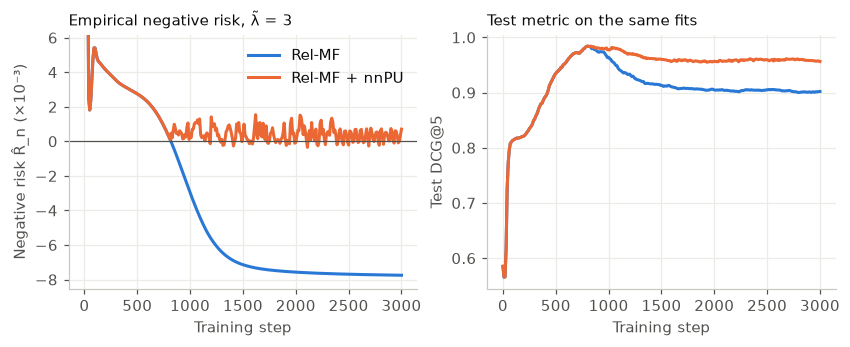

|                                           |   Selected step |   Last step |    Drop |   Budget (steps) |   R̂_n at last step | Selected steps   | Test peak steps   | Test peak − last   | R̂_n first < 0       |
|:------------------------------------------|----------------:|------------:|--------:|-----------------:|-------------------:|:-----------------|:------------------|:-------------------|:--------------------|
| Naive MF                                  |          0.8848 |      0.8775 |  0.0074 |             6000 |             0.0004 | 4000, 5760, 5660 | 2100, 2130, 1800  | 0.0235 to 0.0442   | never, never, never |
| BPR-MF                                    |          0.9755 |      0.9696 |  0.0060 |              100 |                    | 57, 54, 42       | 16, 9, 18         | 0.0158 to 0.0221   |                     |
| WMF                                       |          1.0030 |      1.0021 |  0.0009 |             1500 |             0.0528 | 1170, 1420, 1500 | 150, 130, 2

Rel-MF + nnPU minus Rel-MF at the last step, rule A winners: +0.0551 [+0.0468, +0.0630]  
rare-credit, rule A winners: -0.0103 [-0.0198, +0.0001]  
rare-credit, rule B winners: -0.0595 [-0.0717, -0.0462]  
restricted DCG@1, rule A winners: +0.0295 [+0.0155, +0.0444]  
restricted DCG@1, rule B winners: +0.0693 [+0.0516, +0.0867]
λ̃ = 3, M = 0, seed 42. Rel-MF: R̂_n first below zero at step 820; test peak 0.9842 at step 800, last 0.9020.
nnPU: test peak 0.9842 at step 800, last 0.9563, smallest R̂_n -0.00035.
nnPU minus Rel-MF, rule A winners, at Rel-MF's selected steps, by seed: +0.0080, -0.0004, +0.0034.
At M = 0 on both sides, λ̃ = 3, seed 42: rule A picks differ by -0.0022; against plain Rel-MF's 8 steps within 0.0005 of rule A's maximum, -0.0149 to +0.0023.


In [10]:
lam = select(T, "nnpu", "A").lam_rel
plain = T[(T.family == "relmf") & (T.M == 0) & (T.lam_rel == lam)].sort_values("step")
nn = T[(T.family == "nnpu") & (T.lam_rel == lam)].sort_values("step")
cross = plain[plain.R_n < 0].step.min()
peak = plain.loc[plain.test_dcg5.idxmax()]
pk = nn.loc[nn.test_dcg5.idxmax()]
rn_lines = (f"λ̃ = {lam:g}, M = 0, seed 42. Rel-MF: R̂_n first below zero at step {cross}; test peak {peak.test_dcg5:.4f} at step {peak.step}, last {plain.test_dcg5.iloc[-1]:.4f}.\n"
            f"nnPU: test peak {pk.test_dcg5:.4f} at step {pk.step}, last {nn.test_dcg5.iloc[-1]:.4f}, smallest R̂_n {nn.R_n.min():+.5f}.")
print(rn_lines)
rows = []
for l in sorted(T[T.family == "nnpu"].lam_rel.unique()):
    pl, nl = T[(T.family == "relmf") & (T.M == 0) & (T.lam_rel == l)], T[(T.family == "nnpu") & (T.lam_rel == l)]
    a, b = pl.loc[pl.test_dcg5.idxmax()], nl.loc[nl.test_dcg5.idxmax()]
    first = pl[pl.R_n < 0].step.min()
    rows.append({"λ̃": f"{l:g}", "R̂_n first < 0": "never" if pd.isna(first) else f"{first:.0f}", "Rel-MF test peak": f"{a.test_dcg5:.4f} at {a.step:.0f}",
                 "nnPU test peak": f"{b.test_dcg5:.4f} at {b.step:.0f}", "nnPU − Rel-MF": f"{b.test_dcg5 - a.test_dcg5:+.4f}"})
peaks_md = pd.DataFrame(rows).to_markdown(index=False, disable_numparse=True)
print(peaks_md)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for df, color, label in ((plain, BLUE, "Rel-MF"), (nn, ORANGE, "Rel-MF + nnPU")):
    axes[0].plot(df.step, df.R_n * 1e3, color=color, label=label)
    axes[1].plot(df.step, df.test_dcg5, color=color, label=label)
axes[0].axhline(0, color=INK2, linewidth=0.8)
later = pd.concat([plain, nn]).query("step >= 100").R_n * 1e3  # the first steps start far above zero
axes[0].set_ylim(later.min() - 0.1 * later.abs().max(), later.max() + 0.1 * later.abs().max())
axes[0].set_ylabel("Negative risk R̂_n (×10⁻³)")
axes[1].set_ylabel("Test DCG@5")
axes[0].set_title(f"Empirical negative risk, λ̃ = {lam:g}")
axes[1].set_title("Test metric on the same fits")
for ax in axes:
    ax.set_xlabel("Training step")
axes[0].legend()
plt.savefig(RESULTS / "02_negative_risk.png")
plt.show()



def last_rn(f):
    """R̂_n at the last step of a family's rule A fit (seed 42). Its scale depends on the family's weights."""
    s, q = select(T, f, "A"), T[T.family == f]
    for k in ("c", "eta", "M", "lam_rel"):
        q = q[q[k].isna() if pd.isna(s[k]) else q[k] == s[k]]
    return q.loc[q.step.idxmax()].R_n


def winner_fits(f):
    """A family's final fits at its rule A configuration, one frame per seed."""
    r, q = select(T, f, "A"), Y.traj[(Y.traj.family == f) & (Y.traj.phase == "final")]
    for k in ("c", "eta", "M", "lam_rel"):
        q = q[q[k].isna() if pd.isna(r[k]) else q[k] == r[k]]
    return [g.sort_values("step") for _, g in q.groupby("seed")]


rows = {}
for f in MAIN:
    if f in ("popularity", "ease"):
        continue
    sel, last = Y.all(f, "A"), seed_metrics(score_vectors(Y.scores, f, "last_A"), L)
    rows[LABELS[f]] = {"Selected step": sel[0]["DCG@5"].mean(), "Last step": last[0]["DCG@5"].mean(),
                       "Drop": sel[0]["DCG@5"].mean() - last[0]["DCG@5"].mean(), "Budget (steps)": last_step(f),
                       "R̂_n at last step": None if f == "bpr" else last_rn(f)}
    fits = winner_fits(f)
    gaps = [g.test_dcg5.max() - g.test_dcg5.iloc[-1] for g in fits]
    rows[LABELS[f]] |= {"Selected steps": ", ".join(f"{g.step[g.val_a_snips.idxmax()]:.0f}" for g in fits),
                        "Test peak steps": ", ".join(f"{g.step[g.test_dcg5.idxmax()]:.0f}" for g in fits),
                        "Test peak − last": f"{min(gaps):.4f} to {max(gaps):.4f}",
                        "R̂_n first < 0": None if f == "bpr" else ", ".join(f"{g.step[g.R_n < 0].min():.0f}" for g in fits).replace("nan", "never")}
collapse = pd.DataFrame(rows).T.astype({"Budget (steps)": int})
collapse["R̂_n at last step"] = collapse["R̂_n at last step"].map(lambda v: "" if v is None or pd.isna(v) else f"{v:+.4f}")
print(md(collapse))
a, b = seed_metrics(score_vectors(Y.scores, "nnpu", "last_A"), L), seed_metrics(score_vectors(Y.scores, "relmf", "last_A"), L)
last_ci = compare(a, b, "DCG@5", Y.idx, Y.ideal["DCG@5"].mean())
last_line = f"Rel-MF + nnPU minus Rel-MF at the last step, rule A winners: {last_ci['diff']:+.4f} [{last_ci['lo']:+.4f}, {last_ci['hi']:+.4f}]"
for name, kw, m in (("rare-credit", dict(rel=Y.rare_rel), "DCG@5"), ("restricted DCG@1", dict(rel=Y.rare_rel, mask=mask), "DCG@1")):
    for r in "AB":
        x, y = (seed_metrics(score_vectors(Y.scores, f, f"last_{r}"), L, **kw) for f in ("nnpu", "relmf"))
        last_line += "  \n{}, rule {} winners: {:+.4f} [{:+.4f}, {:+.4f}]".format(name, r, *paired_ci(x[0][m], y[0][m], Y.idx_r))
print(last_line)
at_rel = [n.test_dcg5[n.step == r.step[r.val_a_snips.idxmax()]].iloc[0] - r.test_dcg5[r.val_a_snips.idxmax()] for n, r in zip(winner_fits("nnpu"), winner_fits("relmf"))]
near = plain[plain.val_a_snips >= plain.val_a_snips.max() - 0.0005]
nn_pick = nn.loc[nn.val_a_snips.idxmax()]
rn_lines += ("\nnnPU minus Rel-MF, rule A winners, at Rel-MF's selected steps, by seed: " + ", ".join(f"{v:+.4f}" for v in at_rel) + "."
             f"\nAt M = 0 on both sides, λ̃ = 3, seed 42: rule A picks differ by {nn_pick.test_dcg5 - plain.loc[plain.val_a_snips.idxmax()].test_dcg5:+.4f}; "
             f"against plain Rel-MF's {len(near)} steps within 0.0005 of rule A's maximum, {nn_pick.test_dcg5 - near.test_dcg5.max():+.4f} to {nn_pick.test_dcg5 - near.test_dcg5.min():+.4f}.")
print(rn_lines)

## 5. Ablations: clipping, η and dimension

Grid results (seed 42) with λ̃ and step chosen by each rule inside each row. `M` below the smallest
non-zero θ̂ leaves the objective unchanged, so clipping only matters when `M` exceeds that value.

In [11]:
rows = []
for fam, eta, Ms in (("relmf_eta025", 0.25, (0,)), ("relmf", 0.5, (0, 0.1, 0.3)), ("relmf_eta1", 1.0, (0, 0.03, 0.1))):
    th = theta(d.n_i, eta)
    for M in Ms:
        cut = T[(T.family == fam) & (T.M == M)]
        r, rb = best_cell(cut), best_cell(cut, "B")
        w = 1 / np.maximum(th, M)[d.fit[:, 1]]
        rows.append({"η": f"{eta:g}", "M": f"{M:g}", "min θ̂": f"{th[th > 0].min():.3f}", "mean weight": f"{w.mean():.2f}", "max weight": f"{w.max():.1f}",
                     "λ̃": f"{r.lam_rel:g}", "step": f"{r.step:.0f}", "test DCG@5": f"{r.test_dcg5:.4f}", "rare-credit": f"{r.rare_credit5:.4f}",
                     "B: test DCG@5": f"{rb.test_dcg5:.4f}", "B: rare-credit": f"{rb.rare_credit5:.4f}"})
abl_md = pd.DataFrame(rows).to_markdown(index=False, disable_numparse=True)
print(abl_md)
eta_md = show_diffs(diff_table(Y, [("relmf_eta025", "relmf"), ("relmf_eta1", "relmf")], rules=("A",)))
print(eta_md)

S = Y.traj[Y.traj.phase == "sens"]
rows = []
for f in ("naive", "relmf"):
    base = best_cell(T[(T.family == f)])
    row = {"family": LABELS[f], f"d={DIM}": f"{base.test_dcg5:.4f} / {base.rare_credit5:.4f}"}
    for dim in SENS_DIMS:
        r = best_cell(S[(S.family == f) & (S.d == dim)])
        row[f"d={dim}"] = f"{r.test_dcg5:.4f} / {r.rare_credit5:.4f}"
    rows.append(row)
sens = pd.DataFrame(rows)[["family", f"d={SENS_DIMS[0]}", f"d={DIM}", f"d={SENS_DIMS[1]}"]]
print(sens.to_markdown(index=False))


def within(family, budget):
    """3-seed test DCG@5 and rare-credit of a family's rule A finals, picking the step per seed within a step budget."""
    fits = [g[g.step <= budget] for g in winner_fits(family)]
    picks = [g.loc[g.val_a_snips.idxmax()] for g in fits]
    return np.mean([r.test_dcg5 for r in picks]), np.mean([r.rare_credit5 for r in picks]), ", ".join(f"{r.step:.0f}" for r in picks)


rows = []
for f, old in (("naive", 3000), ("scar", 1500), ("nnpu", 1500), ("balanced", 1500), ("relmf_eta025", 1500)):
    a, b = within(f, old), within(f, last_step(f))
    rows.append({"family": LABELS[f].split(" (")[0], "earlier budget": old, "current budget": last_step(f), "steps picked, earlier": a[2], "steps picked, current": b[2],
                 "DCG@5, earlier": a[0], "DCG@5, current": b[0], "rare-credit, earlier": a[1], "rare-credit, current": b[1]})
budget = pd.DataFrame(rows)
rel_a, rel_r = Y.all("relmf", "A")[0]["DCG@5"].mean(), Y.rare("relmf", "A")[0]["DCG@5"].mean()
wmf_a = Y.all("wmf", "A")[0]["DCG@5"].mean()
n_old = budget.iloc[0]
budget_line = (f"Rel-MF over naive MF, rule A, at naive MF's earlier budget (no CI): {rel_a - n_old['DCG@5, earlier']:+.4f} ({rel_a / n_old['DCG@5, earlier'] - 1:+.1%}) on all items, "
               f"{rel_r - n_old['rare-credit, earlier']:+.4f} on rare-credit. WMF over naive MF: {wmf_a / n_old['DCG@5, earlier'] - 1:+.1%}.")
budget_md = budget.to_markdown(index=False, floatfmt=".4f")
print(budget_md)
print(budget_line)
write("02_ablations.md", "### Clipping and η (seed 42, each rule inside each row; columns without a prefix are rule A)\n", abl_md,
      "\n### η variants against η = 0.5 (3 seeds, rule A)\n", eta_md,
      "\n### Dimension: test DCG@5 / rare-credit DCG@5 (seed 42, rule A step)\n", sens.to_markdown(index=False),
      "\n### Selected step against last step, test DCG@5 (3 seeds, rule A; BPR-MF counts epochs; R̂_n at last step is seed 42)\n", md(collapse), f"\n{last_line}",
      "\n### The fits in the negative-risk figure\n", rn_lines,
      "\n### Test peak by λ̃, Rel-MF M = 0 against nnPU (seed 42, read from the test curve)\n", peaks_md,
      "\n### What the raised step budgets changed (rule A, 3 seeds, same configuration, picks re-made within each budget)\n", budget_md, f"\n{budget_line}")

| η    | M    | min θ̂   | mean weight   | max weight   | λ̃   | step   | test DCG@5   | rare-credit   | B: test DCG@5   | B: rare-credit   |
|:-----|:-----|:--------|:--------------|:-------------|:----|:-------|:-------------|:--------------|:----------------|:-----------------|
| 0.25 | 0    | 0.190   | 1.82          | 5.3          | 3   | 2740   | 0.9307       | 0.4036        | 0.9367          | 0.4056           |
| 0.5  | 0    | 0.036   | 3.70          | 27.7         | 3   | 1010   | 0.9614       | 0.4932        | 0.9723          | 0.4382           |
| 0.5  | 0.1  | 0.036   | 3.65          | 10.0         | 3   | 980    | 0.9729       | 0.4935        | 0.9746          | 0.4673           |
| 0.5  | 0.3  | 0.036   | 2.52          | 3.3          | 3   | 2960   | 0.9222       | 0.4140        | 0.9455          | 0.3349           |
| 1    | 0    | 0.001   | 20.38         | 764.7        | 1   | 1190   | 0.8993       | 0.4785        | 0.9470          | 0.4734           |
| 1    | 0.03 | 0.

## 6. Calibration

Ranking is scale-free but a bid is not, so it matters what `σ` estimates. On uniform-exposure
rows, naive MF should converge to the click rate `θγ` and Rel-MF to `(θ/θ̂)γ`. Eq. 12 sets `θ̂ = 1`
for the hottest item, whose true exposure is well below 1. If `θ̂` is proportional to `θ`, Rel-MF's
`σ` is the relevance rate scaled down by one constant. Fitting that constant on `val_B`
(`ĉ = mean σ / mean R`) separates a scale error from a shape error, and the `σ_Rel-MF / γ̂` column
by popularity tests the premise only at the minimiser, which these fits do not reach. The same table checks the mechanism: `σ_naive / σ_Rel-MF` should
follow `θ̂_i`. The Rel-MF winner clips at `M = 0.1`, so the target is strictly `max(θ̂_i, 0.1)`, which
differs from `θ̂_i` only in the two least popular bins. The training click rate `n_i / users` shows how
far the fit is from the population minimiser: naive MF's `σ` should come close to it.

| model                    |   λ per unlabelled weight |   mean σ |   mean R |   item-level minimiser |   raw ECE |   ĉ on val_B |   ECE of σ/ĉ |   ECE of σ/ĉ, fit by fit |
|:-------------------------|--------------------------:|---------:|---------:|-----------------------:|----------:|-------------:|-------------:|-------------------------:|
| Naive MF                 |                    1.0000 |   0.0165 |   0.0887 |                 0.0073 |    0.0721 |       0.2034 |       0.0178 |                   0.0160 |
| Rel-MF                   |                   10.9492 |   0.0672 |   0.0887 |                 0.0267 |    0.0241 |       0.8224 |       0.0166 |                   0.0160 |
| Rel-MF + nnPU            |                   11.0939 |   0.0834 |   0.0887 |                 0.0270 |    0.0203 |       1.0219 |       0.0204 |                   0.0184 |
| SCAR, c = 1/10 (near c*) |                   30.0000 |   0.1055 |   0.0887 |                 0.0717 |    0.0211 |       1.3001 |     

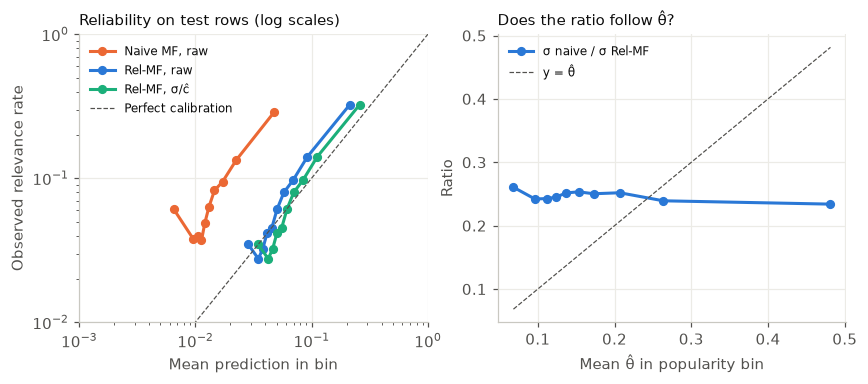

In [12]:
def sigma(family, rule="A"):
    v = score_vectors(Y.scores, family, rule)
    return np.mean([1 / (1 + np.exp(-x)) for x in v.values()], axis=0)


rel = (d.rand[:, 2] >= THRESHOLD).astype(float)
test_rows, val_rows = d.split == "test", d.split == "val_b"
sig = {f: sigma(f) for f in ("naive", "relmf", "nnpu", "scar_c10", "scar_c500", "scar", "wmf", "balanced")}
sig_b = {f: sigma(f, "B") for f in ("naive", "relmf")}
item = d.rand[:, 1]
# The minimiser w¹ / (w¹ + w⁰) of each objective at the item's training click rate.
click, N, D = d.n_i / d.m, d.Y.sum(), d.Y.size
a_, b_ = D / (2 * (D - N)), D / (2 * N)
th05 = theta(d.n_i, 0.5)
minimiser = {"naive": click, "relmf": click / np.maximum(th05, 0.1), "nnpu": click / th05, "scar_c10": np.clip(10 * click, 0, 1), "scar_c500": np.clip(500 * click, 0, 1), "scar": np.clip(30 * click, 0, 1),
             "wmf": 100 * click / (100 * click + 1 - click), "balanced": np.clip(b_ * click / th05 / (a_ * (1 - click) + b_ * click), 0, 1)}
# λ per unit of weight on an unlabelled pair, at each fit's rule A choice.
pos = d.fit[:, 1]
scale = {"naive": 1, "relmf": (1 / np.maximum(th05, 0.1)[pos]).mean(), "nnpu": (1 / th05[pos]).mean(), "scar_c10": 10, "scar_c500": 500, "scar": 30, "wmf": 100, "balanced": b_ / a_ * (1 / th05[pos]).mean()}
lam_of = {f: select(T, f, "A").lam_rel for f in ("naive", "relmf", "nnpu", "scar", "wmf", "balanced")} | {"scar_c10": select(T[np.isclose(T.c, 0.1)], "scar", "A").lam_rel, "scar_c500": select(Y.traj, "scar", "A", phase="control_grid").lam_rel}


def ece_by_fit(f):
    """Mean ECE of σ/ĉ with ĉ fitted fit by fit."""
    out = []
    for x in score_vectors(Y.scores, f, "A").values():
        p_ = 1 / (1 + np.exp(-x))
        out.append(reliability(p_[test_rows] / (p_[val_rows].mean() / rel[val_rows].mean()), rel[test_rows])[1])
    return np.mean(out)


names = {"naive": LABELS["naive"], "relmf": LABELS["relmf"], "nnpu": LABELS["nnpu"], "scar_c10": "SCAR, c = 1/10 (near c*)", "scar_c500": "SCAR, c′ = 500", "scar": "SCAR, winner (c = 1/30)",
         "wmf": "WMF, winner (c′ = 100)", "balanced": "Rel-MF balanced, winner"}
rows, curves = [], {}
for f, s in sig.items():
    c_hat = s[val_rows].mean() / rel[val_rows].mean()
    tab_raw, ece_raw = reliability(s[test_rows], rel[test_rows])
    tab_cal, ece_cal = reliability(s[test_rows] / c_hat, rel[test_rows])
    curves[f] = tab_raw, tab_cal
    rows.append({"model": names[f], "λ per unlabelled weight": lam_of[f] * scale[f], "mean σ": s[test_rows].mean(), "mean R": rel[test_rows].mean(),
                 "item-level minimiser": minimiser[f][item[test_rows]].mean(), "raw ECE": ece_raw, "ĉ on val_B": c_hat, "ECE of σ/ĉ": ece_cal, "ECE of σ/ĉ, fit by fit": ece_by_fit(f)})
cal = pd.DataFrame(rows)
print(md(cal, index=False))

bins = np.array_split(np.argsort(d.n_i, kind="stable"), 10)
rows = []
for k, b in enumerate(bins):
    m = np.isin(item, b) & test_rows
    gamma = rel[m].mean()
    rows.append({"popularity bin": str(k + 1), "mean n_i": d.n_i[b].mean(), "training click rate": d.n_i[b].mean() / d.m, "mean θ̂": th05[b].mean(), "γ̂ (mean R)": gamma,
                 "σ naive": sig["naive"][m].mean(), "σ Rel-MF": sig["relmf"][m].mean(),
                 "σ naive / σ Rel-MF": sig["naive"][m].mean() / sig["relmf"][m].mean(), "max(θ̂, 0.1)": theta(d.n_i, 0.5, 0.1)[b].mean(),
                 "ratio, rule B": sig_b["naive"][m].mean() / sig_b["relmf"][m].mean(),
                 "σ Rel-MF / γ̂": sig["relmf"][m].mean() / gamma})
pop = pd.DataFrame(rows)
print(md(pop, index=False))
write("02_calibration.md", "### Calibration on the test rows (rule A fits; σ averaged over 3 seeds before binning, SCAR c = 1/10 is seed 42 only)\n", md(cal, index=False),
      f"\nECE of a constant at val_B's relevance rate: {reliability(np.full(test_rows.sum(), rel[val_rows].mean()), rel[test_rows])[1]:.4f}",
      "\n### By item popularity (rule A unless the column says B)\n", md(pop, index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
ax = axes[0]
for (tab, color, label) in ((curves["naive"][0], ORANGE, "Naive MF, raw"), (curves["relmf"][0], BLUE, "Rel-MF, raw"), (curves["relmf"][1], AQUA, "Rel-MF, σ/ĉ")):
    ax.plot(tab.pred, tab.obs, "-o", color=color, markersize=5, label=label)
lim = [1e-3, 1]
ax.plot(lim, lim, color=INK2, linewidth=0.8, linestyle="--", label="Perfect calibration")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(0.01, 1)
ax.set_xlabel("Mean prediction in bin"); ax.set_ylabel("Observed relevance rate")
ax.set_title("Reliability on test rows (log scales)")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(pop["mean θ̂"], pop["σ naive / σ Rel-MF"], "-o", color=BLUE, markersize=5, label="σ naive / σ Rel-MF")
ax.plot(pop["mean θ̂"], pop["mean θ̂"], color=INK2, linewidth=0.8, linestyle="--", label="y = θ̂")
ax.set_xlabel("Mean θ̂ in popularity bin"); ax.set_ylabel("Ratio")
ax.set_title("Does the ratio follow θ̂?")
ax.legend(fontsize=8)
plt.savefig(RESULTS / "02_calibration.png")
plt.show()

## 7. Coat (directional only)

Coat is much smaller: 200 test users with a positive and 25 in `val_B`. It was not part of the
paper, so there is no reference number. Read the CIs, not the point estimates.

In [13]:
C = Finals("coat")
coat_main = md(main_table(C, ["DCG@5", "Recall@5", "AP@5"]))
coat_diffs = show_diffs(diff_table(C, DIFFS[:3] + [("popularity", "relmf")]))
print(coat_main)
print(coat_diffs)
write("02_coat.md", "### Coat, directional only (rule A unless prefixed with B; 3 seeds)\n", coat_main, "\n### Paired differences\n", coat_diffs)

|                                           |   DCG@5 |   Recall@5 |   AP@5 |   Rare@5 |   B: DCG@5 |   B: Rare@5 |
|:------------------------------------------|--------:|-----------:|-------:|---------:|-----------:|------------:|
| Random (analytic)                         |  0.6982 |     0.3398 | 0.2216 |   0.4056 |            |             |
| Popularity                                |  0.9627 |     0.4828 | 0.3514 |   0.0184 |     0.9627 |      0.0184 |
| Naive MF                                  |  0.8504 |     0.4208 | 0.2970 |   0.3055 |     0.9359 |      0.1366 |
| BPR-MF                                    |  0.9949 |     0.5101 | 0.3888 |   0.3046 |     0.9793 |      0.3104 |
| EASE                                      |  0.9655 |     0.4871 | 0.3619 |   0.2058 |     0.9494 |      0.2081 |
| WMF                                       |  1.0351 |     0.5394 | 0.4007 |   0.1901 |     1.0267 |      0.2040 |
| SCAR (constant θ)                         |  1.0050 |     0.5060 | 0.3

## Takeaways

Yahoo! R3, rule A unless stated. Differences are 3-seed paired bootstraps with 95% CIs. Points marked "seed 42" come from the grid.

* **Rel-MF beats naive MF, and with λ tuned per family the paper's Yahoo! ordering does not replicate.** Rel-MF beats naive MF on DCG@5 by +0.0883 [+0.0764, +0.1013] (+10.0%, 14.3% of the headroom) and on
  rare-credit by +0.0434 [+0.0253, +0.0594] (+9.9%, 1,073 users, 1,561 rare positives). Rule B gives +0.0653 [+0.0530, +0.0787] and +0.1152 [+0.0973, +0.1338]. All seeds agree on all four
  signs, so the sign test fixed after single-seed probes and before the grid holds. The paper runs naive MF only in its semi-synthetic experiment. Rel-MF stays below WMF, one of its two Yahoo! baselines, on all items, -0.0299 [-0.0412, -0.0191]
  and under rule B -0.0449 [-0.0556, -0.0338], and so does balanced, -0.0149 [-0.0227, -0.0073] and -0.0112 [-0.0206, -0.0022], all at d = 100. ExpoMF, the other, was not run.
* **A constant weight can replace the gain.** WMF gains +0.1182 [+0.1050, +0.1318] on all items and +0.0334 [+0.0151, +0.0508] on rare-credit, at c′ = 100.
  In the vocabulary of section 2, rare-credit reads (a), WMF ≈ SCAR ≈ Rel-MF. All items go further, WMF ≈ SCAR > Rel-MF, with Rel-MF minus SCAR at -0.0318 [-0.0432, -0.0206]. Between family winners,
  neither (b) nor (c) holds. Rule B differs in one place: SCAR sits below WMF on all items and above it on rare-credit (+0.0140, lower bound +0.0006), and Rel-MF separates from neither on rare-credit.
  That gap compares c′ = 30 with c′ = 300, so it does not read as (b): WMF's own move from c′ = 100 to 300 gives +0.0130 and -0.0230, and against WMF at c′ = 100 SCAR is +0.0016 and -0.0090 (3 seeds, no CI).
  At the same c′ and λ̃ the PU term raises rare-credit in 13 of 16 cells under rule A and 15 of 16 under rule B, and splits all items, 8 and 12 of 16 (seed 42, no CIs). Tuning absorbs it.
* **Scale confounds that comparison.** Rel-MF's `θ̂`, at η = 0.5 and clipped at M = 0.1, sets its mean weight on positives to 3.65, and moving η or M changes the shape as well. WMF and SCAR tune theirs directly.
  The constant families reach at most 0.9303 on all items and 0.3575 on rare-credit at c′ = 3, the nearest cell, and 0.9744 and 0.4298 at c′ = 10, 2.7 times that scale, against Rel-MF's 0.9729 and 0.4935 (seed 42).
  They pull ahead on all items at c′ of 30 or more, except SCAR at c′ = 500, the control below (0.9251).
* **At the same high scale, the popularity shape lifts rare items.** Balanced keeps the shape and weights positives about 136 times more, a mean of about 500 times an unlabelled pair. The nearest control, SCAR at
  c′ = 500, has no shape but a stronger PU term, -499 on each positive against balanced's mean of -366; the exact shape-free objective was not fitted. Against it balanced ties on all items under rule B, +0.0036 [-0.0043, +0.0118], and is higher on rare-credit, +0.0802 [+0.0691, +0.0911]. Under rule A balanced is higher on both, +0.0628 [+0.0530, +0.0731] and +0.0217 [+0.0087, +0.0337], but
  the all-item gap comes from rule A picking SCAR's lowest λ̃ (0.9251 / 0.4931): at balanced's λ̃ = 0.3 SCAR scores 0.9876 / 0.4896 against 0.9869 / 0.5081 (scores: seed 42).
* **Against the tuned constants balanced trades a little all-item accuracy for rare items.** It beats WMF on rare-credit by +0.0386 [+0.0277, +0.0492] and is lower on all items, -0.0149 [-0.0227, -0.0073] (rule B: +0.0772 [+0.0656, +0.0898] and
  -0.0112 [-0.0206, -0.0022]). A large constant does not do this alone: WMF at c′ = 300 and 1000, either side of balanced's scale, reaches rare-credit 0.4737 and 0.4759 under rule A against balanced's 0.5081, and under rule B no constant at any c′ exceeds
  0.4777 against balanced's 0.5298. A smaller constant can match it under rule A: WMF at c′ = 30 scores 0.9882 / 0.5132 against balanced's 0.9869 / 0.5081, but only steps 310 to 330 of that fit beat balanced on both, and rule B gives it 0.9980 / 0.4127 (these two sentences: seed 42).
  Balanced also beats plain Rel-MF on both metrics under both rules.
* **The lift is against popular items.** Credit DCG@1 favours Rel-MF and balanced (0.1597 each) over WMF (0.1302) and SCAR (0.1168). Among rare items alone, restricted DCG@1 favours WMF and SCAR (0.5266 each) over balanced (0.5039) and Rel-MF (0.4986).
  Over balanced the differences are +0.0227 [+0.0068, +0.0410] (WMF) and +0.0227 [+0.0009, +0.0460] (SCAR), over Rel-MF +0.0280 [+0.0043, +0.0522] and +0.0280 [+0.0043, +0.0516]. Under rule B balanced ties them, 0.5390 against 0.5294 and 0.5228, with WMF minus balanced
  -0.0096 [-0.0267, +0.0093] and SCAR minus balanced -0.0162 [-0.0413, +0.0093].
* **A penalty at ranking time does about as well at DCG@5.** On the rule B WMF fits, with per-seed α (0.26, 0.24, 0.22) set on `val_B` to reach balanced's rare-credit, the difference from balanced covers 0 on both metrics, -0.0006 [-0.0086, +0.0079] and +0.0046 [-0.0060, +0.0157]. With this α, set at DCG@5, it is below
  balanced on rare-credit at DCG@1 and DCG@3, -0.0205 [-0.0342, -0.0068] and -0.0115 [-0.0223, -0.0006], but the gap moves with α: set at DCG@1 (0.28, 0.28, 0.34) the two gaps are -0.0087 [-0.0217, +0.0040] and +0.0110 [-0.0010, +0.0226]. With per-seed α (0.10, 0.18, 0.18) maximising all-item DCG@5 on `val_B` it adds +0.0515 [+0.0445, +0.0584] to rare-credit for -0.0047 [-0.0100, +0.0007] on all items. One penalty form, tried after seeing the results.
* **nnPU protects a model that trains too long, though not its rare-credit, and its effect on the peak depends on λ̃.** At λ̃ = 3, M = 0, seed 42, `R̂_n` crosses zero at step 820, just after test DCG@5 peaks at 0.9842 at step 800. Rel-MF ends at 0.9020 and nnPU at 0.9563, and over 3 seeds the last-step difference between
  the rule A winners (Rel-MF at M = 0.1, nnPU at M = 0) is +0.0551 [+0.0468, +0.0630], and restricted DCG@1 is +0.0295 [+0.0155, +0.0444]. Rare-credit is not protected, -0.0103 [-0.0198, +0.0001] and under rule B -0.0595 [-0.0717, -0.0462]: late Rel-MF puts more rare items above popular ones, which that reading rewards. The fits coincide up to the crossing, so nnPU cannot lower that peak, and here it does not raise it. At λ̃ ≤ 1 the crossing comes first (steps 320 to 430, against Rel-MF peaks at steps 430 to 500), and nnPU's peak is higher
  by 0.0090 to 0.0205 (seed 42, read from the test curve). Its best point across λ̃ is 0.9886 against 0.9854 for Rel-MF across M, a one-seed gap about the size of the seed spread, and no validation rule selects it.
  At the selected step nnPU is lower under rule A, -0.0145 [-0.0237, -0.0045], which misses my expectation of "no lower". Rule A picks nnPU late (steps 2090 to 2170, long after the test peak), and that alone covers it: at Rel-MF's own selected steps nnPU is +0.0080, -0.0004 and +0.0034 by seed (no CI). The winners also differ in M, which these fits do not size: at M = 0 on both sides (λ̃ = 3, seed 42, no CI) the difference is -0.0022, but -0.0149 to +0.0023 across plain Rel-MF's steps within 0.0005 of rule A's maximum. Under rule B the winners' difference is +0.0059 [-0.0007, +0.0122], with rare-credit +0.0354 [+0.0266, +0.0443].
* **A negative `R̂_n` alone does not predict the fall.** On the SCAR and balanced rule A winners it is below zero from step 40 and from step 0, before test DCG@5 peaks at steps 280 to 520 and 660 to 1290, and it ends at -0.1159 and -1.2616, each on its own weight scale. From test peak to last step they lose 0.0034 to 0.0095 and 0.0037 to 0.0083
  across seeds, against 0.0827 to 0.0863 for Rel-MF (M = 0.1), whose `R̂_n` first goes below zero at step 840, after its peak at steps 790 to 820. I did not establish why.
* **η and clipping.** η = 0.25 is lower on both metrics, -0.0388 [-0.0504, -0.0268] and -0.0801 [-0.0966, -0.0626]. At η = 1 the all-item score is lower, -0.0305 [-0.0405, -0.0191], and rare-credit does not separate, -0.0016 [-0.0146, +0.0119]. At η = 0.5, M = 0.1 moves test DCG@5 from 0.9614 to 0.9729, and M = 0.3 pushes the mean weight down to 2.52 and scores
  0.9222, close to SCAR at c′ = 3 (0.9288). At η = 1, M = 0.1 helps under rule A (0.8993 to 0.9508) and M = 0.03 does not (0.8910); under rule B both help (0.9470 to 0.9726 and 0.9733). The M comparisons are seed 42.
* **Dimension does not change the order.** Rel-MF stays above naive MF at d = 30, 100 and 200 (0.9733, 0.9729, 0.9801 against 0.8759, 0.8944, 0.8991, seed 42).
* **No stronger model family beats Rel-MF.** BPR-MF ties it on all items, +0.0024 [-0.0084, +0.0140]. EASE is lower under rule A, -0.0597 [-0.0753, -0.0448], and ties under rule B, -0.0001 [-0.0140, +0.0132]. Both are lower on rare-credit under both rules. The families above
  Rel-MF on all items are WMF, SCAR and balanced, the same model with different weights.
* **Calibration.** Naive MF's mean `σ` is 0.0165 where the relevance rate is 0.0887, and Rel-MF's is 0.0672. A constant from `val_B` (ĉ = 0.2034 and 0.8224) takes the ECE of `σ` averaged over the 3 seeds from 0.0721 to 0.0178 and from 0.0241 to 0.0166; fit by fit it lands at 0.0160 for both. Three expectations fail. That ECE is not small: a constant at `val_B`'s relevance rate, which ranks nothing, scores 0.0072. Rel-MF's ĉ is 0.82, where I expected below 0.36.
  And `σ_naive / σ_Rel-MF` is flat at 0.23 to 0.26, and falls from 0.56 to 0.31 under rule B, while its target `max(θ̂, 0.1)` runs from 0.10 to 0.48. A wrong η cannot explain that, because true exposure cancels in the ratio. The fits chosen for ranking are far from the population minimiser: naive MF's `σ` runs from 0.0125 to 0.0261 across popularity bins while the training
  click rate runs from 0.0007 to 0.0393. Under rule A the level of `σ` orders by `λ = λ̃ · w̄_pos` per unit of unlabelled weight, not by the positive weights alone (0.0672 Rel-MF at λ = 11, 0.1538 SCAR c′ = 500 at 50, 0.2008 SCAR c′ = 30 at 90, 0.2130 WMF at 100, 0.2888 balanced at 151). The item-level minimiser has no λ̃ and rises with the weights over a wider range (0.0267, 0.8978, 0.1758, 0.2956, 0.9977 for the same five), and `σ_Rel-MF / γ̂` falls from 0.94 to 0.60 with popularity. So `σ` needs its own calibration step on exploration traffic before it goes near a bid.
* **Coat, directional only (200 test users with a relevant item).** Rel-MF is above naive MF on all items, +0.1066 [+0.0558, +0.1625] and +0.0631 [+0.0035, +0.1162] under rule B. Rare-credit splits, -0.0364 [-0.0918, +0.0207] and +0.1329 [+0.0873, +0.1853]. Popularity (0.9627) and Rel-MF (0.9570) do not separate under rule A, +0.0058 [-0.0732, +0.0798]. Under rule B nnPU
  equals Rel-MF exactly, because every seed's selected step comes before `R̂_n` first goes negative.